# EDA

Preguntas sobre el tracking crudo: qué hay en el archivo, la velocidad del balón, cuántos jugadores se ven.

Los fallos de una solución y la comparación con la referencia se miran en `06_revision.ipynb`, que carga el `frame_df.csv` escrito por `05_algoritmo.ipynb`. Este notebook no corre el algoritmo.

`frame_id` es el frame del vídeo y del CSV que se entrega. Coincide con el índice de la fila. `tracking_frame_id` es el id original del archivo de tracking, y vale `frame_id + 1`.


In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
from kloppy import metrica


import games
import time

paths = games.asset_paths(source='tactical')


# Summary of Changes and observations


- Observation: Ball speed is present in atd file, has some entries with values but in frame_df all values are empty. Kloppy metrica doesn't include the field, we created own reader for speed and merged it with frame_df
- Observation: Players have: x, y, d and s. D field is not present in file and all values are empty.
- Observation: Players info we have 22 players on the pitch. But tracker has 46 trackers. As commented in the data description:  "Slots appear, vanish and swap identity as the tracker loses and re-acquires people. Expect around 22 tracked objects during play — the mean over graded frames is 20.5, and it occasionally exceeds 22 when the tracker duplicates someone. You get positions and team membership, nothing more, so any analysis you build has to be collective rather than per-player". Strategies to relign players by positions, check duplicates when we have more than 22 players might be usefull. Also file marks slots:  24 y el 46 as Goalkeeper. Others as unknown. 


# Conclusions


- Ball speed read from the file doesn't seem to apport extra information. Ball speed ms is computed from ball position comparing, prev frame position if exist with current.


## Match Related Info

- https://www.fcbarcelona.es/es/partidos/116220/fc-barcelona-athletic-club-la-liga-2024-2025
- https://www.laliga.com/partido/temporada-2024-2025-laliga-ea-sports-fc-barcelona-athletic-club-2


## Radu review ideas


- Duplicated pos for players are just 2000 frames or less during match, review if this can help us improve
- Ball speed was geenrated it from ball position from on frame compared with previous. So missin balls if we have the speed we can check if its out of the field. just an estimator. Detectar fueras de campo de la pelota.


## Read full dataset evaluation:


In [2]:
t0 = time.perf_counter()
dataset = metrica.load_tracking_epts(
    meta_data=paths["atd_meta"],
    raw_data=paths["atd_raw"],
)
elapsed = time.perf_counter() - t0
print("%d frames in %.1f s" % (len(dataset.records), elapsed))


199319 frames in 24.0 s


199319 frames in 26.7 s


In [3]:
t1 = time.perf_counter()
frame_df = dataset.to_df()
elapsed = time.perf_counter() - t1
print("%d frames in %s s" % (frame_df.shape[0], elapsed))


199319 frames in 9.43758141703438 s


In [4]:
# Kloppy's frame_id starts at 1. The submission CSV and the video start at 0.
# After this cell, frame_id is the deliverable frame and matches the row index.
# tracking_frame_id keeps the original id. It is frame_id + 1.
frame_df["tracking_frame_id"] = frame_df["frame_id"].astype(int)
frame_df["frame_id"] = frame_df["tracking_frame_id"] - 1
frame_df = frame_df.reset_index(drop=True)
frame_df[["frame_id", "tracking_frame_id"]].head(3)


,frame_id,tracking_frame_id
0,0,1
1,1,2
2,2,3


## Ball speed


In [5]:
def load_ball_speed(raw_path, n_frames):
    """Ball speed from the raw ATD, in the unit the XML declares (kph).

    The ball is the third ':' field of each line, and speed is its third comma
    value. Kloppy drops that value, so this reads the text directly. Index i is
    video frame i. NaN where the file has no speed.
    """
    speed = np.full(n_frames, np.nan)
    with open(raw_path) as handle:
        for line in handle:
            frame, _, ball = line.split(":", 2)
            value = ball.rstrip("\n").split(",")[2]
            if value != "NaN":
                speed[int(frame) - 1] = float(value)
    return speed


ball_speed = load_ball_speed(paths["atd_raw"], games.GAMES[games.GAME]["n_video_frames"])
print("numeric speeds: %d of %d" % (np.isfinite(ball_speed).sum(), len(ball_speed)))

# frame_id is the video frame. ball_speed[i] is the same frame.
frame_df["ball_speed"] = ball_speed[frame_df["frame_id"].to_numpy()]
frame_df["ball_speed"].value_counts(dropna=False)


numeric speeds: 20971 of 199319


ball_speed
NaN         178348
1.387768         2
1.191529         2
0.545196         2
1.074279         2
             ...  
1.293019         1
1.267769         1
1.236331         1
1.198929         1
1.155892         1
Name: count, Length: 20968, dtype: int64

In [6]:
frame_df


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s,tracking_frame_id
0,1,0 days 00:00:00.040000,0,None,None,NaN,NaN,None,NaN,0.33411,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,1
1,1,0 days 00:00:00.080000,1,None,None,NaN,NaN,None,NaN,0.33404,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,2
2,1,0 days 00:00:00.120000,2,None,None,NaN,NaN,None,NaN,0.33396,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,3
3,1,0 days 00:00:00.160000,3,None,None,NaN,NaN,None,NaN,0.33389,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,4
4,1,0 days 00:00:00.200000,4,None,None,NaN,NaN,None,NaN,0.33382,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199314,1,0 days 02:12:52.600000,199314,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,199315
199315,1,0 days 02:12:52.640000,199315,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,199316
199316,1,0 days 02:12:52.680000,199316,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,199317
199317,1,0 days 02:12:52.720000,199317,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,199318


In [7]:
round((frame_df[frame_df["ball_x"].isna() == False].shape[0] / frame_df.shape[0]) * 100, 2)


56.94

In [8]:
round((frame_df[frame_df["ball_y"].isna() == False].shape[0] / frame_df.shape[0]) * 100, 2)


56.94

In [9]:
frame_df[(frame_df["ball_x"].isna() == False) & (frame_df["ball_y"].isna() != False)]


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s,tracking_frame_id


In [10]:
frame_df[(frame_df["ball_x"].isna() != False) & (frame_df["ball_y"].isna() == False)]


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s,tracking_frame_id


In [11]:
frame_df[frame_df["ball_speed"].isna() == False]


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s,tracking_frame_id
4817,1,0 days 00:03:12.720000,4817,None,None,NaN,NaN,None,1.495544,NaN,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,4818
4818,1,0 days 00:03:12.760000,4818,None,None,NaN,NaN,None,1.503945,NaN,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,4819
4819,1,0 days 00:03:12.800000,4819,None,None,NaN,NaN,None,1.514737,NaN,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,4820
4820,1,0 days 00:03:12.840000,4820,None,None,NaN,NaN,None,1.528223,NaN,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,4821
4821,1,0 days 00:03:12.880000,4821,None,None,NaN,NaN,None,1.544720,NaN,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,4822
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
194375,1,0 days 02:09:35.040000,194375,None,None,NaN,NaN,None,1.293019,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,194376
194376,1,0 days 02:09:35.080000,194376,None,None,NaN,NaN,None,1.267769,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,194377
194377,1,0 days 02:09:35.120000,194377,None,None,NaN,NaN,None,1.236331,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,194378
194378,1,0 days 02:09:35.160000,194378,None,None,NaN,NaN,None,1.198929,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,194379


In [12]:
round((frame_df[frame_df["ball_speed"].isna() == False].shape[0] / frame_df.shape[0]) * 100, 2)


10.52

In [13]:
frame_df["ball_speed"].value_counts(dropna=False)


ball_speed
NaN         178348
1.387768         2
1.191529         2
0.545196         2
1.074279         2
             ...  
1.293019         1
1.267769         1
1.236331         1
1.198929         1
1.155892         1
Name: count, Length: 20968, dtype: int64

In [14]:
frame_df[["ball_speed"]].sort_values(by="ball_speed", ascending=False)


,ball_speed
55484,7.271594
55485,7.268975
55483,7.256962
55486,7.247259
55482,7.227014
...,...
199314,NaN
199315,NaN
199316,NaN
199317,NaN


In [15]:
frame_df[(frame_df["ball_x"].isna() == False) & 
        (frame_df["ball_y"].isna() == False) & 
        (frame_df["ball_speed"].isna() == False)]


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s,tracking_frame_id
54835,1,0 days 00:36:33.440000,54835,None,None,0.60347,0.40058,None,2.431114,NaN,...,NaN,0.69926,0.65142,None,2.048434,0.93506,0.52074,None,1.264032,54836
54836,1,0 days 00:36:33.480000,54836,None,None,0.60188,0.39312,None,2.465222,NaN,...,NaN,0.69881,0.65061,None,2.013304,0.93469,0.52021,None,1.272192,54837
54837,1,0 days 00:36:33.520000,54837,None,None,0.60037,0.38537,None,2.496498,NaN,...,NaN,0.69836,0.64981,None,1.980121,0.93432,0.51968,None,1.280440,54838
54838,1,0 days 00:36:33.560000,54838,None,None,0.59895,0.37732,None,2.524590,NaN,...,NaN,0.69791,0.64902,None,1.949132,0.93394,0.51914,None,1.288766,54839
54839,1,0 days 00:36:33.600000,54839,None,None,0.59760,0.36898,None,2.549170,NaN,...,NaN,0.69746,0.64823,None,1.920526,0.93356,0.51860,None,1.297140,54840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187817,1,0 days 02:05:12.720000,187817,None,None,0.90583,0.52977,None,3.005412,0.68340,...,NaN,0.45733,0.55711,None,2.984490,0.96168,0.51646,None,NaN,187818
187818,1,0 days 02:05:12.760000,187818,None,None,0.90564,0.53141,None,2.953807,0.68460,...,NaN,0.45798,0.55853,None,2.979266,0.96168,0.51646,None,NaN,187819
187819,1,0 days 02:05:12.800000,187819,None,None,0.90532,0.53297,None,2.891255,0.68579,...,NaN,0.45861,0.55994,None,2.973401,0.96168,0.51646,None,NaN,187820
187820,1,0 days 02:05:12.840000,187820,None,None,0.90489,0.53448,None,2.817650,0.68698,...,NaN,0.45923,0.56135,None,2.966633,0.96168,0.51646,None,NaN,187821


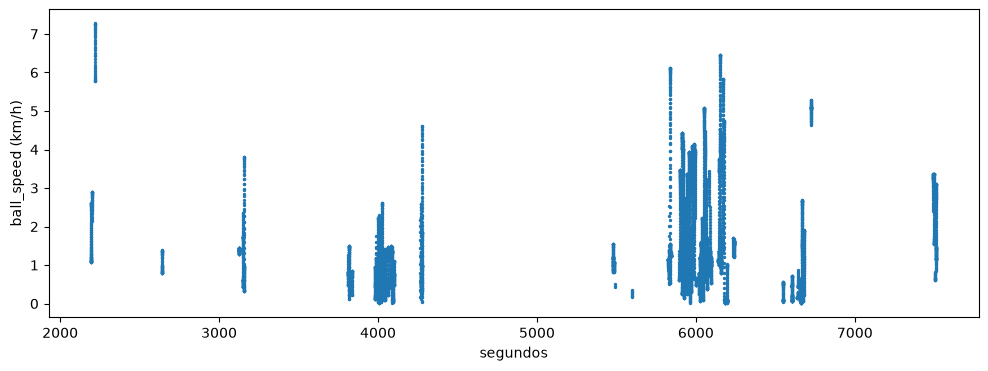

In [16]:
subset = frame_df[
    frame_df["ball_x"].notna()
    & frame_df["ball_y"].notna()
    & frame_df["ball_speed"].notna()
]
plt.figure(figsize=(12, 4))
plt.scatter((subset["frame_id"]) / 25, subset["ball_speed"], s=2)
plt.xlabel("segundos")
plt.ylabel("ball_speed (km/h)")
plt.show()


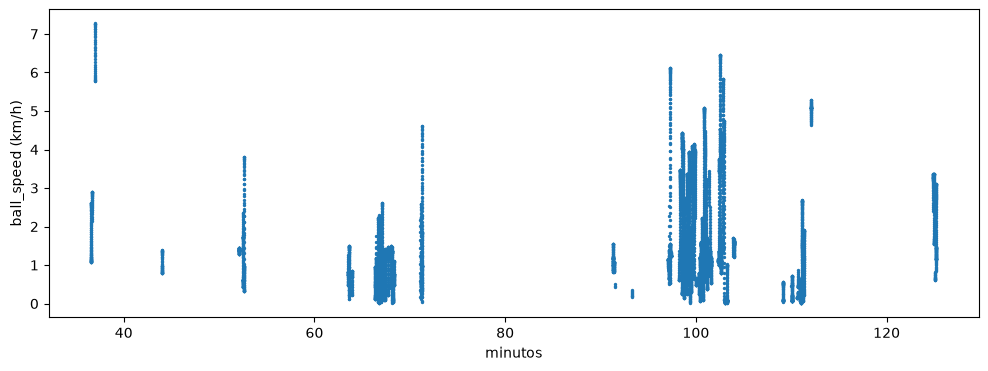

In [17]:
subset = frame_df[
    frame_df["ball_x"].notna()
    & frame_df["ball_y"].notna()
    & frame_df["ball_speed"].notna()
]
plt.figure(figsize=(12, 4))
plt.scatter((subset["frame_id"]) / (25 * 60), subset["ball_speed"], s=2)
plt.xlabel("minutos")
plt.ylabel("ball_speed (km/h)")
plt.show()


## Compute own ball speed


In [18]:
L, W, fps = 105.3, 68.0, 25


In [19]:
dx = frame_df["ball_x"].diff() * L
dy = frame_df["ball_y"].diff() * W
seen = frame_df["ball_x"].notna() & frame_df["ball_y"].notna()


In [20]:
frame_df["ball_speed_mps"] = np.hypot(dx, dy) * fps
frame_df.loc[~(seen & seen.shift(fill_value=False)), "ball_speed_mps"] = np.nan


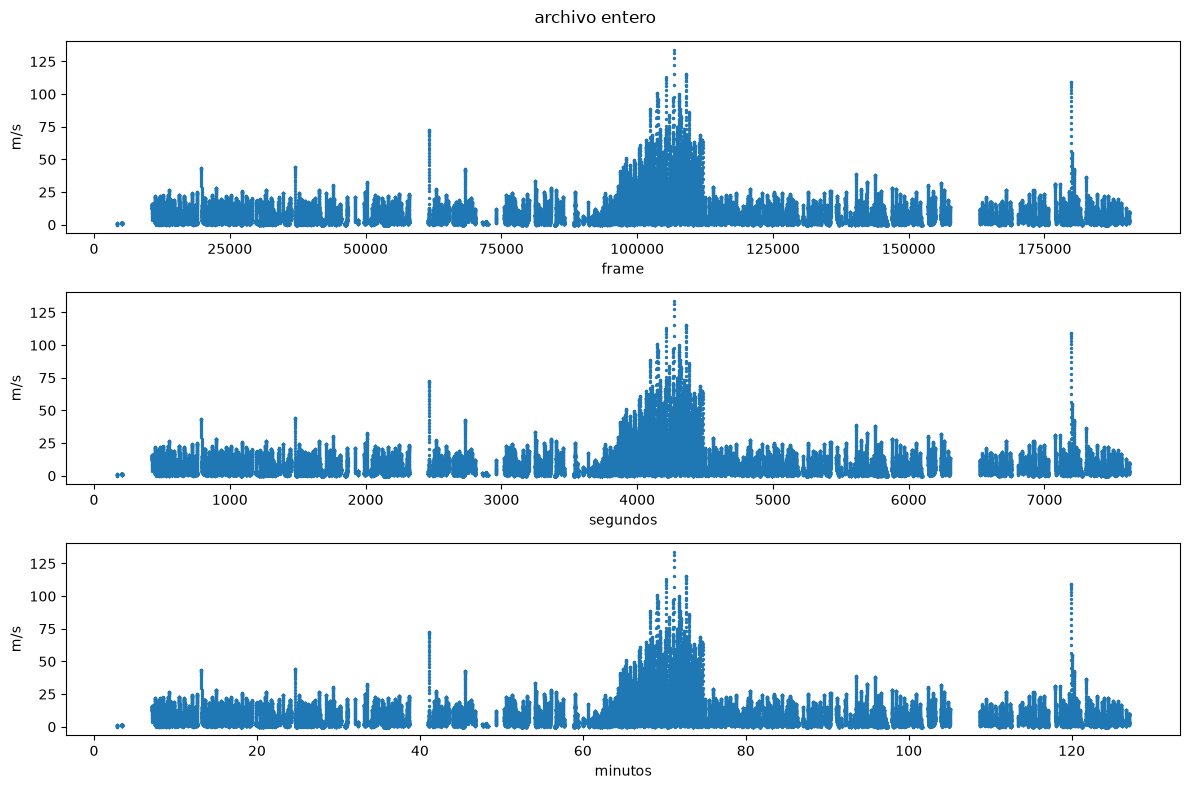

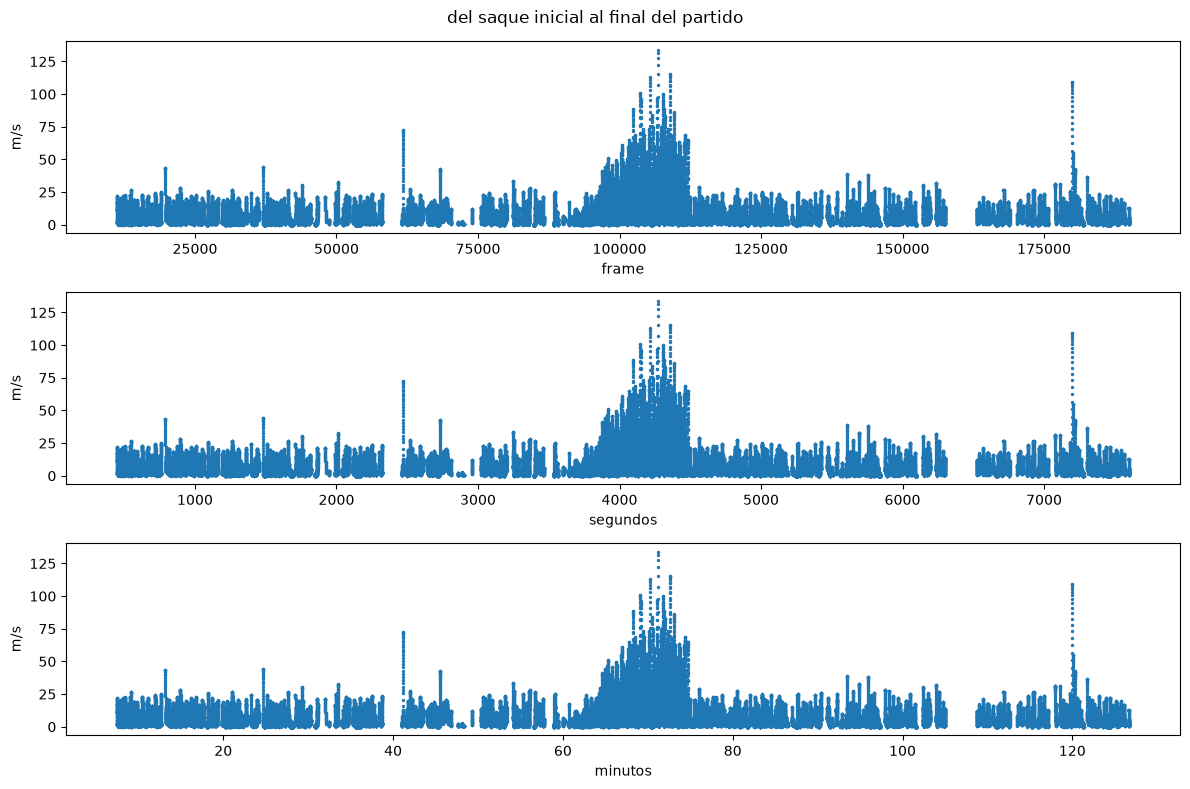

In [21]:
def plot_speed(df, title):
    part = df.loc[df["ball_speed_mps"].notna()]
    video_frame = part["frame_id"]
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharey=True)
    for ax, x, label in zip(
        axes,
        (video_frame, video_frame / 25, video_frame / (25 * 60)),
        ("frame", "segundos", "minutos"),
    ):
        ax.scatter(x, part["ball_speed_mps"], s=2)
        ax.set_xlabel(label)
        ax.set_ylabel("m/s")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_speed(frame_df, "archivo entero")

# Saque inicial de la primera parte (11185) hasta el último frame puntuado (190197).
# El descanso queda en medio y casi no tiene puntos.
video_frame = frame_df["frame_id"]
play = frame_df[video_frame.between(11185, 190197)]
plot_speed(play, "del saque inicial al final del partido")


## Players tracker


In [22]:
frame_df


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s,tracking_frame_id,ball_speed_mps
0,1,0 days 00:00:00.040000,0,None,None,NaN,NaN,None,NaN,0.33411,...,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,1,NaN
1,1,0 days 00:00:00.080000,1,None,None,NaN,NaN,None,NaN,0.33404,...,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,2,NaN
2,1,0 days 00:00:00.120000,2,None,None,NaN,NaN,None,NaN,0.33396,...,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,3,NaN
3,1,0 days 00:00:00.160000,3,None,None,NaN,NaN,None,NaN,0.33389,...,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,4,NaN
4,1,0 days 00:00:00.200000,4,None,None,NaN,NaN,None,NaN,0.33382,...,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,5,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199314,1,0 days 02:12:52.600000,199314,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,199315,NaN
199315,1,0 days 02:12:52.640000,199315,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,199316,NaN
199316,1,0 days 02:12:52.680000,199316,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,199317,NaN
199317,1,0 days 02:12:52.720000,199317,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,199318,NaN


In [23]:
x_cols = [f"{i}_x" for i in range(1, 47)]
s_cols = [f"{i}_s" for i in range(1, 47)]


In [24]:
frame_df["n_players"] = frame_df[x_cols].notna().sum(axis=1)
frame_df["n_players_speed"] = frame_df[s_cols].notna().sum(axis=1)


In [25]:
# cut just match:
video_frame = frame_df["frame_id"]
play = frame_df[video_frame.between(11185, 190197)]


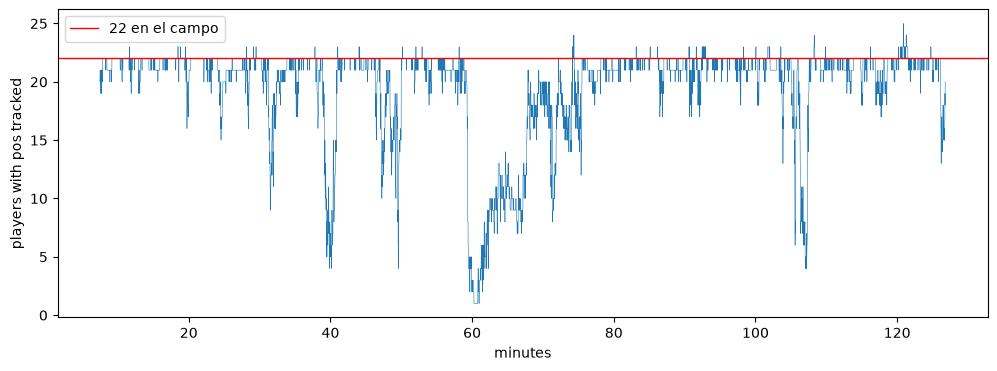

In [26]:
plt.figure(figsize=(12, 4))
plt.plot(video_frame.loc[play.index] / (25 * 60), play["n_players"], lw=0.4)
plt.axhline(22, color="red", lw=1, label="22 en el campo")
plt.xlabel("minutes")
plt.ylabel("players with pos tracked")
plt.legend()
plt.show()


In [27]:
n = len(play)
print("match frames: %d" % n)
print("fewer than 22: %d (%.1f%%)" % ((play["n_players"] < 22).sum(), 100 * (play["n_players"] < 22).mean()))
print("exactly 22: %d (%.1f%%)" % ((play["n_players"] == 22).sum(), 100 * (play["n_players"] == 22).mean()))
print("more than 22: %d (%.1f%%)" % ((play["n_players"] > 22).sum(), 100 * (play["n_players"] > 22).mean()))
print("22 or more: %d (%.1f%%)" % ((play["n_players"] >= 22).sum(), 100 * (play["n_players"] >= 22).mean()))
print("mean players with a position: %.2f" % play["n_players"].mean())
print("mean players with a speed: %.2f" % play["n_players_speed"].mean())


match frames: 179013
fewer than 22: 96658 (54.0%)
exactly 22: 78606 (43.9%)
more than 22: 3749 (2.1%)
22 or more: 82355 (46.0%)
mean players with a position: 19.59
mean players with a speed: 17.94


From players tracked positions at first glance we can understand something happend on minutes 30 aprox, 40, 50, and more pronunciated at 60 minute and 110 aprox.


In [28]:
frame_df


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,45_d,45_s,46_x,46_y,46_d,46_s,tracking_frame_id,ball_speed_mps,n_players,n_players_speed
0,1,0 days 00:00:00.040000,0,None,None,NaN,NaN,None,NaN,0.33411,...,None,NaN,0.06057,0.39965,None,NaN,1,NaN,7,5
1,1,0 days 00:00:00.080000,1,None,None,NaN,NaN,None,NaN,0.33404,...,None,NaN,0.06057,0.39965,None,NaN,2,NaN,8,5
2,1,0 days 00:00:00.120000,2,None,None,NaN,NaN,None,NaN,0.33396,...,None,NaN,0.06057,0.39965,None,NaN,3,NaN,8,5
3,1,0 days 00:00:00.160000,3,None,None,NaN,NaN,None,NaN,0.33389,...,None,NaN,0.06057,0.39965,None,NaN,4,NaN,8,5
4,1,0 days 00:00:00.200000,4,None,None,NaN,NaN,None,NaN,0.33382,...,None,NaN,0.06057,0.39965,None,NaN,5,NaN,8,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199314,1,0 days 02:12:52.600000,199314,None,None,NaN,NaN,None,NaN,NaN,...,None,NaN,0.96168,0.51646,None,NaN,199315,NaN,8,6
199315,1,0 days 02:12:52.640000,199315,None,None,NaN,NaN,None,NaN,NaN,...,None,NaN,0.96168,0.51646,None,NaN,199316,NaN,8,6
199316,1,0 days 02:12:52.680000,199316,None,None,NaN,NaN,None,NaN,NaN,...,None,NaN,0.96168,0.51646,None,NaN,199317,NaN,8,6
199317,1,0 days 02:12:52.720000,199317,None,None,NaN,NaN,None,NaN,NaN,...,None,NaN,0.96168,0.51646,None,NaN,199318,NaN,8,6


## Dónde seguir

Una regla nueva se escribe en `05_algoritmo.ipynb`. Después de ejecutarla y de pasar `run_evaluation.py`, los frames concretos se miran en `06_revision.ipynb`.
